# DS483 – SMS Spam Detection
## Task 2 Review: TF-IDF Representation and Cosine Similarity

**Contributor:** Bishr Othman (GitHub: BishrSeu)
**Date:** 2026-11-03
**Repository:** https://github.com/saadalshammari-62/DS483-SMS-Spam-Detection

### Objective
Review and re-run the Task 2 code from `DS483_SMS_Spam_Project.ipynb` (cells 12–14): the TF-IDF representation,
the most-similar-message examples, the class-level similarity statistics and the 1-NN check. Every number is
compared with `results.json` and with Section 2 of the report (`DS483_Project_Reordered.docx`).

The data loading, split and preprocessing code below is copied **unchanged** from the project notebook so the review
uses exactly the same pipeline as the group.

## 1. Same setup as the project notebook (imports, data, split, preprocessing)

In [1]:
import os, re, io, zipfile, json, urllib.request, warnings
from functools import lru_cache
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import sklearn

warnings.filterwarnings("ignore")
SEED = 42
RESULTS = {}
os.makedirs("figures", exist_ok=True)
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

# reference numbers saved by the project notebook
REF = json.load(open("results.json"))

scikit-learn 1.6.1 | pandas 2.3.3


In [2]:
# ---- copied from project notebook cell 4 ----
DROP_DUPLICATES = True

def load_sms():
    fname = "SMSSpamCollection"
    if not os.path.exists(fname):
        url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
        data = urllib.request.urlopen(url, timeout=60).read()
        zipfile.ZipFile(io.BytesIO(data)).extract(fname)
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(fname, sep="\t", header=None, names=["label", "text"], quoting=3, encoding=enc)
        except UnicodeDecodeError:
            continue

raw = load_sms()
df = raw.drop_duplicates().reset_index(drop=True) if DROP_DUPLICATES else raw.copy()
df["y"] = (df["label"] == "spam").astype(int)
train_df, tmp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
val_df, test_df  = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df["y"], random_state=SEED)
train_df, val_df, test_df = [d.copy().reset_index(drop=True) for d in (train_df, val_df, test_df)]
print("train / val / test:", len(train_df), len(val_df), len(test_df))
assert (len(train_df), len(val_df), len(test_df)) == (REF["data"]["train"], REF["data"]["val"], REF["data"]["test"])

train / val / test: 3619 776 776


In [3]:
# ---- copied from project notebook cell 9 (ablation loop omitted; the selected setting is taken from results.json) ----
STOP = set(stopwords.words("english"))
_stemmer = PorterStemmer()
@lru_cache(maxsize=None)
def stem(w): return _stemmer.stem(w)

URL_RE   = re.compile(r"(?:https?://\S+|www\.\S+|\b[\w-]+\.(?:com|co\.uk|net|org|info|biz)\b\S*)", re.I)
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
MONEY_RE = re.compile(r"[£$€]\s?\d[\d,]*(?:\.\d+)?|\b\d+(?:\.\d+)?\s?(?:p|pence|pounds?|gbp|usd)\b", re.I)
PHONE_RE = re.compile(r"\b\d{5,}\b")
NUM_RE   = re.compile(r"\b\d+\b")

def normalise(text):
    t = EMAIL_RE.sub(" emailtok ", text)
    t = URL_RE.sub(" urltok ", t)
    t = MONEY_RE.sub(" moneytok ", t)
    t = PHONE_RE.sub(" phonetok ", t)
    t = NUM_RE.sub(" numtok ", t)
    return t.lower()

def preprocess(text, stop=True, stem_words=True):
    toks = re.findall(r"[a-z]+", normalise(text))
    if stop:       toks = [w for w in toks if w not in STOP]
    if stem_words: toks = [stem(w) for w in toks]
    return " ".join(toks)

assert REF["preprocessing_selected"] == "+ stemming"
PREP = dict(stop=False, stem_words=True)
for d in (train_df, val_df, test_df):
    d["clean"] = d.text.map(lambda t: preprocess(t, **PREP))
print("Preprocessing used for Task 2:", REF["preprocessing_selected"], PREP)

Preprocessing used for Task 2: + stemming {'stop': False, 'stem_words': True}


## 2. Re-run the Task 2 code exactly as in the project notebook (cells 12–14)

In [4]:
# ---- project notebook cell 12 ----
tfidf = TfidfVectorizer(sublinear_tf=True)
X_train = tfidf.fit_transform(train_df.clean)
X_test_t = tfidf.transform(test_df.clean)
terms = np.array(tfidf.get_feature_names_out())
print("TF-IDF matrix (train):", X_train.shape, "| density: %.4f%%" % (100 * X_train.nnz / np.prod(X_train.shape)))

top_terms = {}
for lab, name in ((1, "spam"), (0, "ham")):
    m = np.asarray(X_train[train_df.y.values == lab].mean(axis=0)).ravel()
    top_terms[name] = [(terms[i], round(float(m[i]), 4)) for i in np.argsort(-m)[:10]]
display(pd.DataFrame({k: [f"{w} ({s})" for w, s in v] for k, v in top_terms.items()}))
RESULTS["task2_top_tfidf_terms"] = top_terms

TF-IDF matrix (train): (3619, 5180) | density: 0.2532%


,spam,ham
0,phonetok (0.1161),you (0.0447)
1,numtok (0.1099),to (0.0333)
2,moneytok (0.0869),the (0.0272)
3,call (0.07),it (0.0264)
4,to (0.0684),me (0.025)
5,your (0.0477),in (0.0244)
6,free (0.0472),and (0.0225)
7,urltok (0.0368),my (0.0216)
8,for (0.0366),numtok (0.0214)
9,you (0.0363),that (0.0201)


In [5]:
# ---- project notebook cell 13 ----
def most_similar(query, k=5):
    q = tfidf.transform([preprocess(query, **PREP)])
    sims = cosine_similarity(q, X_train).ravel()
    idx = np.argsort(-sims)[:k]
    out = train_df.iloc[idx][["label", "text"]].copy(); out.insert(0, "cosine", sims[idx].round(3))
    return q, idx, out

queries = [test_df[test_df.y == 1].iloc[0].text, test_df[test_df.y == 1].iloc[1].text, test_df[test_df.y == 0].iloc[0].text]
RESULTS["task2_similarity_examples"] = []
for q_text in queries:
    q, idx, out = most_similar(q_text)
    print("\nQUERY:", q_text); display(out)
    contrib = q.multiply(X_train[idx[0]]).toarray().ravel()
    shared = [(terms[i], round(float(contrib[i]), 3)) for i in np.argsort(-contrib)[:5] if contrib[i] > 0]
    print("Terms contributing most to the top match:", shared)
    RESULTS["task2_similarity_examples"].append(dict(query=q_text, top=out.to_dict("records"), shared_terms=shared))


QUERY: Todays Voda numbers ending 5226 are selected to receive a ?350 award. If you hava a match please call 08712300220 quoting claim code 1131 standard rates app 


,cosine,label,text
1038,0.981,spam,Todays Voda numbers ending 7548 are selected to receive a $350 award. If you have a match please call 0871...
3318,0.981,spam,Todays Voda numbers ending 1225 are selected to receive a £50award. If you have a match please call 087123...
338,0.873,spam,Phony £350 award - Todays Voda numbers ending XXXX are selected to receive a £350 award. If you have a mat...
2295,0.840,spam,Todays Voda numbers ending with 7634 are selected to receive a £350 reward. If you have a match please cal...
1556,0.550,spam,todays vodafone numbers ending with 0089(my last four digits) are selected to received a £350 award. If yo...


Terms contributing most to the top match: [('voda', 0.088), ('standard', 0.084), ('quot', 0.08), ('app', 0.077), ('match', 0.067)]

QUERY: Dear Voucher Holder, 2 claim this weeks offer, at your PC go to http://www.e-tlp.co.uk/expressoffer Ts&Cs apply.2 stop texts txt STOP to 80062.


,cosine,label,text
2200,0.866,spam,"Dear Voucher Holder, To claim this weeks offer, at your PC please go to http://www.wtlp.co.uk/text. Ts&Cs ..."
2991,0.375,spam,Last chance 2 claim ur £150 worth of discount vouchers-Text YES to 85023 now!SavaMob-member offers mobile ...
3339,0.374,spam,Dear Voucher holder Have your next meal on us. Use the following link on your pc 2 enjoy a 2 4 1 dining ex...
2341,0.319,spam,"Today's Offer! Claim ur £150 worth of discount vouchers! Text YES to 85023 now! SavaMob, member offers mob..."
3045,0.318,spam,+123 Congratulations - in this week's competition draw u have won the £1450 prize to claim just call 09050...


Terms contributing most to the top match: [('holder', 0.118), ('pc', 0.099), ('ts', 0.095), ('appli', 0.069), ('voucher', 0.066)]

QUERY: Awesome question with a cute answer: Someone asked a boy "how is ur life?" . . He smiled &amp; answered: . . "She is fine!" Gudnite


,cosine,label,text
2476,0.316,spam,Ur balance is now £500. Ur next question is: Who sang 'Uptown Girl' in the 80's ? 2 answer txt ur ANSWER t...
1289,0.202,ham,"Could you not read me, my Love ? I answered you"
560,0.194,ham,Gudnite....tc...practice going on
1329,0.193,ham,Haven't heard anything and he's not answering my texts so I'm guessing he flaked. That said the jb is fant...
2596,0.187,ham,So now my dad is gonna call after he gets out of work and ask all these crazy questions.


Terms contributing most to the top match: [('answer', 0.172), ('question', 0.059), ('ur', 0.047), ('is', 0.038)]


{'ham_ham': 0.0197, 'spam_spam': 0.0834, 'ham_spam': 0.0194}


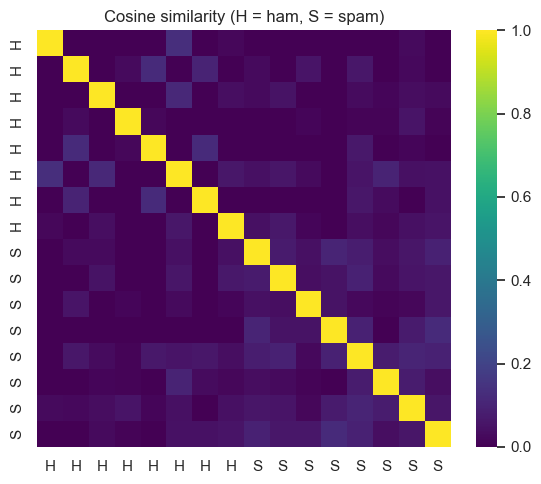

1-NN (cosine) on test: {'accuracy': 0.9716, 'precision': 0.9318, 'recall': 0.8367, 'f1': 0.8817}


In [6]:
# ---- project notebook cell 14 ----
rs = np.random.RandomState(SEED)
ns = min(300, int(train_df.y.sum()))
ham_i  = rs.choice(np.where(train_df.y == 0)[0], ns, replace=False)
spam_i = rs.choice(np.where(train_df.y == 1)[0], ns, replace=False)
def mean_sim(a, b, same):
    S = cosine_similarity(X_train[a], X_train[b])
    if same: S = S[~np.eye(len(a), dtype=bool)]
    return float(S.mean())
sim_stats = dict(ham_ham=mean_sim(ham_i, ham_i, True), spam_spam=mean_sim(spam_i, spam_i, True), ham_spam=mean_sim(ham_i, spam_i, False))
print({k: round(v, 4) for k, v in sim_stats.items()})

sel = np.r_[ham_i[:8], spam_i[:8]]
plt.figure(figsize=(5.8, 5))
sns.heatmap(cosine_similarity(X_train[sel]), cmap="viridis", xticklabels=["H"]*8+["S"]*8, yticklabels=["H"]*8+["S"]*8, vmin=0, vmax=1)
plt.title("Cosine similarity (H = ham, S = spam)"); plt.tight_layout(); plt.savefig("figures/t2_similarity_heatmap.png", dpi=200); plt.show()

nn = np.asarray(cosine_similarity(X_test_t, X_train).argmax(axis=1)).ravel()
nn_pred = train_df.y.values[nn]
nn_stats = dict(accuracy=float(accuracy_score(test_df.y, nn_pred)), precision=float(precision_score(test_df.y, nn_pred)),
                recall=float(recall_score(test_df.y, nn_pred)), f1=float(f1_score(test_df.y, nn_pred)))
print("1-NN (cosine) on test:", {k: round(v, 4) for k, v in nn_stats.items()})
RESULTS["task2_similarity_stats"] = sim_stats; RESULTS["task2_1nn_test"] = nn_stats

## 3. Reproducibility check against `results.json`

Every Task 2 value produced above is compared with the value stored by the project notebook.

In [7]:
def close(a, b, tol=1e-4):
    return abs(float(a) - float(b)) <= tol

checks = []
for cls in ("spam", "ham"):
    same = [(w, round(s, 4)) for w, s in RESULTS["task2_top_tfidf_terms"][cls]] == [(w, round(s, 4)) for w, s in REF["task2_top_tfidf_terms"][cls]]
    checks.append(("Top-10 TF-IDF terms – " + cls, same))
for i, (mine, ref) in enumerate(zip(RESULTS["task2_similarity_examples"], REF["task2_similarity_examples"]), 1):
    checks.append((f"Query {i}: text", mine["query"] == ref["query"]))
    checks.append((f"Query {i}: top-5 cosine scores", [r["cosine"] for r in mine["top"]] == [r["cosine"] for r in ref["top"]]))
    checks.append((f"Query {i}: top-5 neighbour texts", [r["text"] for r in mine["top"]] == [r["text"] for r in ref["top"]]))
    checks.append((f"Query {i}: shared terms", [tuple(x) for x in mine["shared_terms"]] == [tuple(x) for x in ref["shared_terms"]]))
for k in ("ham_ham", "spam_spam", "ham_spam"):
    checks.append((f"Mean similarity {k}", close(RESULTS["task2_similarity_stats"][k], REF["task2_similarity_stats"][k])))
for k in ("accuracy", "precision", "recall", "f1"):
    checks.append((f"1-NN {k}", close(RESULTS["task2_1nn_test"][k], REF["task2_1nn_test"][k])))
chk = pd.DataFrame(checks, columns=["check", "matches results.json"])
display(chk)
print(f"{chk['matches results.json'].sum()} / {len(chk)} checks match")

,check,matches results.json
0,Top-10 TF-IDF terms – spam,True
1,Top-10 TF-IDF terms – ham,True
2,Query 1: text,True
3,Query 1: top-5 cosine scores,True
4,Query 1: top-5 neighbour texts,True
5,Query 1: shared terms,True
6,Query 2: text,True
7,Query 2: top-5 cosine scores,True
8,Query 2: top-5 neighbour texts,True
9,Query 2: shared terms,True


21 / 21 checks match


## 4. Correctness tests of the TF-IDF / cosine implementation

### 4.1 No leakage: the vocabulary comes from the training split only

In [8]:
vocab = set(tfidf.vocabulary_)
train_tokens = [w for t in train_df.clean for w in t.split()]
test_tokens  = set(w for t in test_df.clean for w in t.split() if len(w) > 1)
oov = test_tokens - vocab
# sklearn's default token_pattern (?u)\b\w\w+\b keeps tokens of 2+ characters only
print("vocabulary == training tokens of length >= 2:", vocab == set(w for w in train_tokens if len(w) > 1), "| size", len(vocab))
one = pd.Series([w for w in train_tokens if len(w) == 1]).value_counts()
print(f"one-letter tokens silently dropped by TfidfVectorizer: {one.sum()} of {len(train_tokens)} training tokens "
      f"({100 * one.sum() / len(train_tokens):.1f}%) – most common: {dict(one.head(6))}")
print(f"test-only tokens ignored by the vectoriser: {len(oov)} (e.g. {sorted(oov)[:8]})")
empty = int((X_test_t.getnnz(axis=1) == 0).sum())
print("test messages with an all-zero TF-IDF vector:", empty, list(test_df.text[X_test_t.getnnz(axis=1) == 0]))

vocabulary == training tokens of length >= 2: True | size 5180
one-letter tokens silently dropped by TfidfVectorizer: 5602 of 57891 training tokens (9.7%) – most common: {'i': np.int64(2076), 'a': np.int64(892), 'u': np.int64(753), 's': np.int64(399), 'm': np.int64(338), 't': np.int64(328)}
test-only tokens ignored by the vectoriser: 616 (e.g. ['aaniy', 'ab', 'abbey', 'abel', 'abroad', 'absenc', 'accordin', 'accumul'])
test messages with an all-zero TF-IDF vector: 2 [':-) :-)', 'hanks lotsly!']


### 4.2 TF-IDF formula: recompute one message by hand and compare with scikit-learn

In [9]:
# sklearn defaults used here: smooth_idf=True, norm='l2', sublinear_tf=True
n = X_train.shape[0]
dfreq = np.bincount(X_train.indices, minlength=X_train.shape[1])
idf_manual = np.log((1 + n) / (1 + dfreq)) + 1
print("idf matches sklearn:", np.allclose(idf_manual, tfidf.idf_))

doc = test_df.clean.iloc[0]
counts = pd.Series(doc.split()).value_counts()
counts = counts[counts.index.isin(vocab)]
w = {t: (1 + np.log(c)) * idf_manual[tfidf.vocabulary_[t]] for t, c in counts.items()}
norm = np.sqrt(sum(v * v for v in w.values()))
manual = {t: v / norm for t, v in w.items()}
sk = {terms[j]: X_test_t[0, j] for j in X_test_t[0].indices}
print("hand-computed vector matches sklearn:", all(np.isclose(manual[t], sk[t]) for t in sk) and set(manual) == set(sk))
display(pd.DataFrame({"tf": counts, "idf": [idf_manual[tfidf.vocabulary_[t]] for t in counts.index],
                      "weight": [manual[t] for t in counts.index]}).sort_values("weight", ascending=False).round(4).head(8))

idf matches sklearn: True
hand-computed vector matches sklearn: True


,tf,idf,weight
answer,2,6.4216,0.4167
gudnit,1,8.5011,0.3258
cute,1,7.8079,0.2993
awesom,1,6.6293,0.2541
boy,1,6.6293,0.2541
question,1,6.3610,0.2438
smile,1,5.8269,0.2233
amp,1,5.7930,0.2220


### 4.3 Cosine similarity = dot product of the L2-normalised vectors

Because every TF-IDF row has length 1, cosine similarity is just the dot product. This also confirms that the
"terms contributing most" list in cell 13 (element-wise product `q * x`) is an exact decomposition of the cosine score.

In [10]:
row_norms = np.sqrt(np.asarray(X_train.multiply(X_train).sum(axis=1)).ravel())
nz = X_train.getnnz(axis=1) > 0
print("all non-empty training rows have unit length:", np.allclose(row_norms[nz], 1),
      "| empty training rows:", list(train_df.text[~nz]))
q, idx, _ = most_similar(queries[0])
print("cosine_similarity == q · x :", np.allclose(cosine_similarity(q, X_train).ravel(), (X_train @ q.T).toarray().ravel()))
contrib = q.multiply(X_train[idx[0]]).toarray().ravel()
print("sum of term contributions = %.4f, cosine of top match = %.4f" % (contrib.sum(), cosine_similarity(q, X_train[idx[0]])[0, 0]))

all non-empty training rows have unit length: True | empty training rows: ['G.W.R']
cosine_similarity == q · x : True
sum of term contributions = 0.9808, cosine of top match = 0.9808


## 5. Checking the similarity examples in detail

### 5.1 What the vectoriser actually sees for each query

In [11]:
for i, q_text in enumerate(queries, 1):
    print(f"Query {i} ({test_df.label[test_df.text == q_text].iloc[0]})")
    print("  original :", q_text)
    print("  processed:", preprocess(q_text, **PREP))
    q, idx, out = most_similar(q_text)
    print("  top match:", preprocess(train_df.text.iloc[idx[0]], **PREP))
    print()

Query 1 (spam)
  original : Todays Voda numbers ending 5226 are selected to receive a ?350 award. If you hava a match please call 08712300220 quoting claim code 1131 standard rates app 
  processed: today voda number end numtok are select to receiv a numtok award if you hava a match pleas call phonetok quot claim code numtok standard rate app
  top match: today voda number end numtok are select to receiv a moneytok award if you have a match pleas call phonetok quot claim code numtok standard rate app

Query 2 (spam)
  original : Dear Voucher Holder, 2 claim this weeks offer, at your PC go to http://www.e-tlp.co.uk/expressoffer Ts&Cs apply.2 stop texts txt STOP to 80062.
  processed: dear voucher holder numtok claim thi week offer at your pc go to urltok ts cs appli numtok stop text txt stop to phonetok
  top match: dear voucher holder to claim thi week offer at your pc pleas go to urltok ts cs appli

Query 3 (ham)
  original : Awesome question with a cute answer: Someone asked a boy "h

### 5.2 The tie at 0.981 in query 1

The two best matches of query 1 both have cosine 0.981. After preprocessing they differ only in the currency
and the amount, which both become `moneytok`, so after preprocessing they are **identical** – the score is an exact tie
and their order in the table is arbitrary.

In [12]:
q, idx, out = most_similar(queries[0])
s = cosine_similarity(q, X_train[idx[:2]]).ravel()
print("exact scores of the two top matches:", s)
for j in idx[:2]:
    print(" -", preprocess(train_df.text.iloc[j], **PREP))

exact scores of the two top matches: [0.98078362 0.98078362]
 - today voda number end numtok are select to receiv a moneytok award if you have a match pleas call phonetok quot claim code numtok standard rate app
 - today voda number end numtok are select to receiv a moneytok award if you have a match pleas call phonetok quot claim code numtok standard rate app


### 5.3 The `?350` in query 1 is a lost pound sign

The original query is `...receive a ?350 award...`. In the raw dataset file some `£` characters were saved as `?`,
so `MONEY_RE` does not match and the amount becomes `numtok` instead of `moneytok`.

In [13]:
qmark_amount = df.text.str.contains(r"\?\d", regex=True)
pound_amount = df.text.str.contains(r"£\d", regex=True)
print("messages with '£<digit>':", int(pound_amount.sum()), "| messages with '?<digit>':", int(qmark_amount.sum()))
print(df[qmark_amount].label.value_counts().to_string())
print("\nexample:", df[qmark_amount].text.iloc[0][:120])
print("normalise('a ?350 award') ->", normalise("a ?350 award"))
print("normalise('a £350 award') ->", normalise("a £350 award"))

messages with '£<digit>': 217 | messages with '?<digit>': 4
label
spam    4

example: You have won ?1,000 cash or a ?2,000 prize! To claim, call09050000327
normalise('a ?350 award') -> a ? numtok  award
normalise('a £350 award') -> a  moneytok  award


### 5.4 More random queries (not only the first rows of the test set)

The project picks the first two spam and the first ham message of the test set. To see whether the behaviour is
typical, here are the best matches for 5 random spam and 5 random ham test messages.

In [14]:
rs2 = np.random.RandomState(7)
rows = []
for lab in (1, 0):
    for j in rs2.choice(np.where(test_df.y == lab)[0], 5, replace=False):
        q, idx, out = most_similar(test_df.text.iloc[j], k=1)
        rows.append(dict(query_label=test_df.label.iloc[j], query=test_df.text.iloc[j][:70],
                         best_cosine=out.cosine.iloc[0], best_label=out.label.iloc[0], best_match=out.text.iloc[0][:70]))
display(pd.DataFrame(rows))

,query_label,query,best_cosine,best_label,best_match
0,spam,URGENT! Your Mobile number has been awarded with a £2000 prize GUARANT,0.975,spam,WIN URGENT! Your mobile number has been awarded with a £2000 prize GUA
1,spam,Urgent! call 09066350750 from your landline. Your complimentary 4* Ibi,1.000,spam,Urgent! call 09066350750 from your landline. Your complimentary 4* Ibi
2,spam,Thanks 4 your continued support Your question this week will enter u i,0.312,spam,As a Registered Subscriber yr draw 4 a £100 gift voucher will b entere
3,spam,"New Mobiles from 2004, MUST GO! Txt: NOKIA to No: 89545 & collect your",0.997,spam,"500 New Mobiles from 2004, MUST GO! Txt: NOKIA to No: 89545 & collect"
4,spam,Your credits have been topped up for http://www.bubbletext.com Your re,0.353,ham,What's ur pin?
5,ham,Waaaat?? Lololo ok next time then!,0.444,ham,Ok
6,ham,How come i din c ü... Yup i cut my hair...,0.405,ham,No..few hours before.went to hair cut .
7,ham,watever reLation u built up in dis world only thing which remains atla,0.205,ham,"Sorry, I'll call later in meeting any thing related to trade please ca"
8,ham,U wake up already? Thanx 4 e tau sar piah it's quite nice.,0.370,ham,Thanx...
9,ham,Every monday..nxt week vl be completing..,0.273,ham,By monday next week. Give me the full gist


### 5.5 Distribution of the best-match score per class

How close is the nearest training neighbour of each test message?

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,678.0,0.395,0.139,0.000,0.301,0.366,0.449,1.0
spam,98.0,0.653,0.293,0.218,0.329,0.705,0.956,1.0


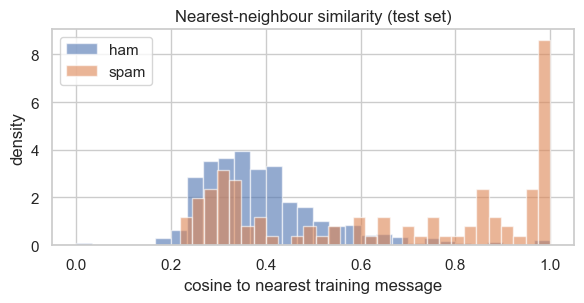

test spam with a near-duplicate in training (cosine >= 0.9): 31 of 98
test ham  with a near-duplicate in training (cosine >= 0.9): 7 of 678


In [15]:
S_test = cosine_similarity(X_test_t, X_train)
best = S_test.max(axis=1)
summary = pd.DataFrame({"label": test_df.label, "best_cosine": best}).groupby("label").best_cosine.describe().round(3)
display(summary)
plt.figure(figsize=(6, 3.2))
for lab in ("ham", "spam"):
    plt.hist(best[test_df.label == lab], bins=30, alpha=.6, label=lab, density=True)
plt.xlabel("cosine to nearest training message"); plt.ylabel("density"); plt.legend(); plt.title("Nearest-neighbour similarity (test set)")
plt.tight_layout(); plt.show()
print("test spam with a near-duplicate in training (cosine >= 0.9):", int(((best >= 0.9) & (test_df.y == 1)).sum()), "of", int(test_df.y.sum()))
print("test ham  with a near-duplicate in training (cosine >= 0.9):", int(((best >= 0.9) & (test_df.y == 0)).sum()), "of", int((test_df.y == 0).sum()))

## 6. Checking the class-level statistics and the 1-NN result

### 6.1 Are the mean similarities stable for other random samples?

In [16]:
rows = []
for seed in range(10):
    r = np.random.RandomState(seed)
    h = r.choice(np.where(train_df.y == 0)[0], ns, replace=False)
    s_ = r.choice(np.where(train_df.y == 1)[0], ns, replace=False)
    rows.append(dict(seed=seed, ham_ham=mean_sim(h, h, True), spam_spam=mean_sim(s_, s_, True), ham_spam=mean_sim(h, s_, False)))
stab = pd.DataFrame(rows)
display(stab[["ham_ham", "spam_spam", "ham_spam"]].agg(["mean", "std", "min", "max"]).round(4))
print("spam_spam / ham_ham ratio over 10 seeds: %.2f – %.2f" % ((stab.spam_spam / stab.ham_ham).min(), (stab.spam_spam / stab.ham_ham).max()))

,ham_ham,spam_spam,ham_spam
mean,0.0210,0.0843,0.0192
std,0.0009,0.0022,0.0009
min,0.0196,0.0816,0.0180
max,0.0222,0.0885,0.0206


spam_spam / ham_ham ratio over 10 seeds: 3.68 – 4.51


### 6.2 1-NN confusion matrix and the missed spam messages

In [17]:
tn, fp, fn, tp = confusion_matrix(test_df.y, nn_pred).ravel()
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}")
miss = np.where((test_df.y.values == 1) & (nn_pred == 0))[0]
display(pd.DataFrame({"spam test message": test_df.text.iloc[miss].str[:80].values,
                      "nearest training ham": train_df.text.iloc[nn[miss]].str[:60].values,
                      "cosine": best[miss].round(3)}).sort_values("cosine").head(10))

TP=82  FN=16  FP=6  TN=672


,spam test message,nearest training ham,cosine
10,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rud,HI BABE U R MOST LIKELY TO BE IN BED BUT IM SO SORRY ABOUT T,0.218
12,WOW! The Boys R Back. TAKE THAT 2007 UK Tour. Win VIP Tickets & pre-book with VI,Booked ticket for pongal?,0.227
5,Sorry! U can not unsubscribe yet. THE MOB offer package has a min term of 54 wee,"Sorry, I can't help you on this.",0.245
13,"Oh my god! I've found your number again! I'm so glad, text me back xafter this m","Me, i dont know again oh",0.260
4,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,"Just checked out, heading out to drop off my stuff now",0.263
2,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Se,"Two fundamentals of cool life: ""Walk, like you are the KING""",0.270
6,Get a brand new mobile phone by being an agent of The Mob! Plus loads more goodi,I liked the new mobile,0.274
1,Would you like to see my XXX pics they are so hot they were nearly banned in the,I cant wait to see you! How were the photos were useful? :),0.281
7,You will recieve your tone within the next 24hrs. For Terms and conditions pleas,Which channel:-):-):):-).,0.296
14,Text PASS to 69669 to collect your polyphonic ringtones. Normal gprs charges app,Just normal only here :),0.298


### 6.3 Extra experiment: k-NN with more neighbours

Not part of the report – a quick check whether one neighbour is a fair summary of cosine-based classification.

In [18]:
order = np.argsort(-S_test, axis=1)
rows = []
for k in (1, 3, 5, 7):
    p = (train_df.y.values[order[:, :k]].mean(axis=1) >= 0.5).astype(int)
    rows.append(dict(k=k, accuracy=accuracy_score(test_df.y, p), precision=precision_score(test_df.y, p),
                     recall=recall_score(test_df.y, p), f1=f1_score(test_df.y, p)))
display(pd.DataFrame(rows).round(4))

,k,accuracy,precision,recall,f1
0,1,0.9716,0.9318,0.8367,0.8817
1,3,0.9807,0.9560,0.8878,0.9206
2,5,0.9845,0.9778,0.8980,0.9362
3,7,0.9807,0.9770,0.8673,0.9189


## 7. Report (Section 2) vs. code and results

| Statement in the report | Value from the code | Status |
|---|---|---|
| TF-IDF with sublinear tf, IDF, L2 normalisation, fitted on training split only | `TfidfVectorizer(sublinear_tf=True)`, `fit_transform(train_df.clean)`; verified in §4.1–4.3 | ✅ Correct |
| Table 5 – top-10 mean TF-IDF terms per class | Identical to cell 12 output (rounded to 3 decimals) | ✅ Correct |
| Query 1: two neighbours at 0.981, contributing terms voda, standard, quot, app | 0.981 / 0.981; voda, standard, quot, app, match | ✅ Correct |
| Table 6 – query 1 text: "receive a **£350** award. If you **have** a match" | Actual dataset text is "receive a **?350** award. If you **hava** a match" | ⚠️ Query was silently corrected in the report |
| Table 6 – query 2 URL "http://www.**etlp**.co.uk/expressoffer" | Actual text is "http://www.**e-tlp**.co.uk/expressoffer" | ⚠️ Small typo |
| Query 2: best match 0.866, next ones about 0.38 | 0.866, then 0.375 / 0.374 | ✅ Correct |
| Query 3 (ham): closest is spam quiz 0.316, ham neighbours about 0.20 | 0.316 spam, then 0.202 / 0.194 / 0.193 / 0.187 ham | ✅ Correct |
| Mean cosine: 0.083 spam–spam, 0.020 ham–ham, 0.019 ham–spam; "about four times" | 0.0834 / 0.0197 / 0.0194 → ratio 4.2 | ✅ Correct |
| 1-NN: accuracy 97.2 %, recall 83.7 %, precision 93.2 %, F1 0.882 | 0.9716 / 0.8367 / 0.9318 / 0.8817 | ✅ Correct |
| "1-nearest**neighbour**" (paragraph after Figure 3) | – | ⚠️ Missing hyphen: "1-nearest-neighbour" |
| Figure 3 – heat-map of 8 ham + 8 spam | Re-generated in cell 14 (`figures/t2_similarity_heatmap.png`) | ✅ Correct |

## 8. Findings

**Confirmed working**
- All Task 2 outputs re-run identically to `results.json` (21 / 21 checks in §3).
- The vectoriser is fitted on the training split only; 616 test-only words are ignored (no leakage).
- The TF-IDF weights match the textbook formula (sublinear tf × smoothed idf, L2-normalised), recomputed by hand in §4.2.
- Cosine similarity equals the dot product of the normalised vectors, so the "terms contributing most" lists are exact.
- The within-class / between-class similarity pattern is stable across 10 random samples (§6.1), so the "spam is about
  four times more self-similar" conclusion does not depend on the chosen seed.

**Issues found**
1. **Report Table 6 does not quote the real query 1.** The dataset text is `...receive a ?350 award. If you hava a match...`;
   the report shows `£350` and `have`. Suggest copying the text exactly (or writing "[£]" and noting the encoding issue).
2. **Encoding problem in the raw data:** some `£` signs appear as `?` (§5.3), so amounts like `?350` become `numtok`
   instead of `moneytok`. It affects a small number of messages and does not change the conclusions, but it is worth one
   sentence in the limitations. A possible fix (only after agreeing with the group, since it changes all later results):
   add `\?` to the currency character class in `MONEY_RE`.
3. Small typos in Section 2 of the report: `etlp` → `e-tlp` (Table 6), `1-nearestneighbour` → `1-nearest-neighbour`.
4. **Near-duplicates across splits:** only *exact* duplicates are removed, so many spam test messages still have a
   near-identical template in training (cosine ≥ 0.9, §5.5). This is realistic for spam, but it makes the 1-NN (and the
   classifiers' results) slightly optimistic. The report already says spam is template-based; one sentence noting this
   effect on the test score would make it more complete.

5. **One-letter tokens are dropped by `TfidfVectorizer`.** Its default `token_pattern` keeps only tokens of 2+ characters,
   so SMS words such as `u`, `r`, `i`, `a` (about 10 % of all training tokens, §4.1) never reach the TF-IDF vectors. Messages
   like `G.W.R` or `:-) :-)` end up as all-zero vectors. This is a design detail the report does not mention; it is
   probably harmless (these words are frequent in both classes), but it could be stated in Section 2.1 – or tested with
   `token_pattern=r"(?u)\b\w+\b"` if the group wants.
6. Query 1's two top matches (both 0.981) are **identical after preprocessing** (§5.2), so their order is arbitrary. Some
   test messages even have a cosine of 1.000 to a training message (§5.4) – different raw text, same processed text.

**Extra result (not in the report):** with k = 5 neighbours instead of 1, cosine k-NN reaches F1 0.936 (recall 0.898)
instead of 0.882 (§6.3). The report's point stands – a lexical nearest-neighbour is weaker than the trained classifiers.

**No change was made to `DS483_SMS_Spam_Project.ipynb`**; the issues above are reported to the group first.